# Statistics Basics for Machine Learning


### 1. Central Tendency & Dispersion (Mean, Median, Mode, Std, IQR)


In [1]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

data = np.array([45, 52, 55, 60, 60, 64, 68, 72, 75, 80, 145])

q25, q75 = np.percentile(data, [25, 75])
iqr = q75 - q25

print("Data:", data)
print(f"Mean:     {np.mean(data):.2f}")
print(f"Median:   {np.median(data):.2f}")
print(f"Mode:     {stats.mode(data, keepdims=True).mode[0]}")
print(f"Variance: {np.var(data):.2f}")
print(f"Std Dev:  {np.std(data):.2f}")
print(f"IQR:      {iqr:.2f} (Q1={q25}, Q3={q75})")


Data: [ 45  52  55  60  60  64  68  72  75  80 145]
Mean:     70.55
Median:   64.00
Mode:     60
Variance: 651.34
Std Dev:  25.52
IQR:      16.00 (Q1=57.5, Q3=73.5)


### 2. Skewness & Kurtosis (Distribution Shape)


Normal Sample -> Skewness: -0.08 | Kurtosis: -0.00
Skewed Sample -> Skewness: 1.75 | Kurtosis: 3.73


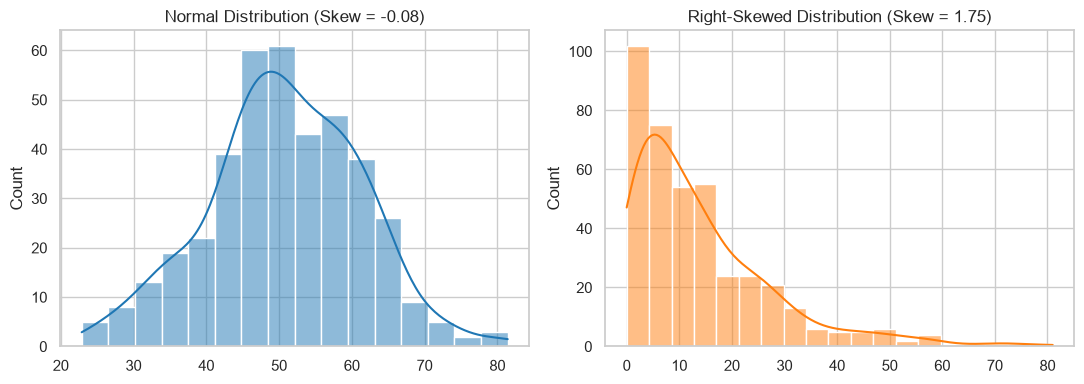

In [2]:
np.random.seed(42)
normal_sample = np.random.normal(loc=50, scale=10, size=400)
skewed_sample = np.random.exponential(scale=15, size=400)

print(f"Normal Sample -> Skewness: {stats.skew(normal_sample):.2f} | Kurtosis: {stats.kurtosis(normal_sample):.2f}")
print(f"Skewed Sample -> Skewness: {stats.skew(skewed_sample):.2f} | Kurtosis: {stats.kurtosis(skewed_sample):.2f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(normal_sample, kde=True, color="#1f77b4", ax=axes[0])
axes[0].set_title(f"Normal Distribution (Skew = {stats.skew(normal_sample):.2f})")

sns.histplot(skewed_sample, kde=True, color="#ff7f0e", ax=axes[1])
axes[1].set_title(f"Right-Skewed Distribution (Skew = {stats.skew(skewed_sample):.2f})")

plt.tight_layout()
plt.show()


### 3. Z-Score & Outlier Detection


In [3]:
z_scores = stats.zscore(data)
outliers = data[np.abs(z_scores) > 2.5]

print("Z-Scores:", np.round(z_scores, 2))
print("Detected Outliers (|Z| > 2.5):", outliers)


Z-Scores: [-1.   -0.73 -0.61 -0.41 -0.41 -0.26 -0.1   0.06  0.17  0.37  2.92]
Detected Outliers (|Z| > 2.5): [145]


### 4. Hypothesis Testing (T-Test & P-Value)


In [4]:
group_a = np.array([65, 68, 70, 72, 66, 71, 69, 73])
group_b = np.array([78, 82, 85, 80, 76, 84, 81, 79])

t_stat, p_val = stats.ttest_ind(group_a, group_b)
print(f"T-Statistic: {t_stat:.4f} | P-Value: {p_val:.4f}")

if p_val < 0.05:
    print("Result: Statistically significant difference (p < 0.05)")
else:
    print("Result: No significant difference")


T-Statistic: -4.8540 | P-Value: 0.0000
Result: Statistically significant difference (p < 0.05)
